<a href="https://colab.research.google.com/github/vivikruppa/RP-II/blob/main/treinamento_RPII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Treinamento usando árvore de regressão (CART)

Este notebook contém o código utilizado para o treinamento de árvores de regressão CART, utilizando o dataset construído para o trabalho de Resolução de Problemas II.

A partir do dataset construído para o trabalho, o treinamento é feito com as variáveis-alvo **Pop_Praca_Relativa** ou **total_parques**. Para utilizá-lo, carregue o CSV, escolha `ALVO` no bloco 1 e execute os blocos 1 a 5. Para mudar o alvo ou os preditores, altere o bloco 1 e execute novamente todos os cinco blocos. Não é necessário repetir o upload se o CSV já contém as colunas necessárias. A troca de alvo não executa os dois treinamentos automaticamente.

| ALVO (nome exato da coluna) | Valores esperados | Unidade de MAE/RMSE |
|---|---|---|
| `Pop_Praca_Relativa` | Proporções de 0 a 1 | Pontos percentuais (p.p.) |
| `total_parques` | Contagens inteiras não negativas | Parques |

O alvo inicia como `Pop_Praca_Relativa`. Para testar parques, use `ALVO = "total_parques"`.


## Preparação adicional — importar bibliotecas e carregar o CSV

Selecione apenas o CSV do dataset. A tabela será carregada em `df`. Este passo prepara os objetos exigidos pelo código original; não executa o treinamento.


In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("Selecione apenas o CSV do dataset.")
nome_arquivo = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]), encoding="utf-8-sig")
print(f"Dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())


Saving dataset_v2_corrigido_atualizado.csv to dataset_v2_corrigido_atualizado.csv
Dataset: 96 linhas e 29 colunas


,cd_ibge,distrito,regioes,codigo_subprefeitura,subprefeituras,Area_km2,Pop,Pop_Dens,Renda,IDSA,...,Empregos_Formais_1000Hab,Vel_Media_Onibus_kmh,Tempo_Medio_Transp_Publico_min,Perc_Acesso_Transp_Massa,Perc_Acesso_Infra_Cicloviaria,Idade_Media_Morrer_Anos,Taxa_Alfabetizacao,Taxa_1_banheiro,Taxa_3_Mais_Banheiro,total_parques
0,355030801,Água Rasa,Leste,25,Mooca,7.13,85788,12023.74,6739.66,0.559,...,295.204,15.3,35,6.7,36.4,73.4,99.202,45.519,13.199,0
1,355030802,Alto de Pinheiros,Oeste,11,Pinheiros,7.50,37359,4983.54,14522.61,0.621,...,808.159,16.7,31,22.0,31.3,79.4,99.701,27.152,45.754,3
2,355030803,Anhanguera,Norte,1,Perus,33.43,75360,2254.20,2832.34,0.644,...,167.051,19.4,58,0.0,0.0,61.5,96.588,67.608,8.179,1
3,355030804,Aricanduva,Leste,26,Aricanduva/Formosa/Carrão,6.85,89574,13081.87,3566.44,0.577,...,197.211,15.7,44,0.0,53.3,69.3,98.004,63.798,8.040,1
4,355030805,Artur Alvim,Leste,21,Penha,6.52,95575,14668.72,2937.61,0.584,...,80.136,16.1,47,21.5,48.8,68.6,97.996,79.108,3.867,0


## Bloco 1 — escolher o alvo e configurar o experimento

É possível editar `ALVO`, `CONFIGURACAO` e `EXCLUIR_EXTRAS`. `EXPERIMENTO` combina o alvo e o nome da configuração automaticamente. Use uma nova `CONFIGURACAO` para preservar resultados de outras escolhas de preditores com o mesmo alvo. Reutilizar a combinação alvo/configuração substitui seu registro.

`USAR_OUTRO_ALVO_COMO_PREDITOR = False` exclui ambos os alvos de `X`. Não há modelo multialvo: cada execução prevê somente o `ALVO` escolhido.

Identificadores (`cd_ibge`, `cod_dist_ibge`, `distrito`, `codigo_subprefeitura`, `index` e colunas `Unnamed:`) ficam excluídos quando presentes, ou seja, não fazem parte das variáveis explicativas. São exclusões adicionais à versão original para não usar identificadores nem essa relação matemática como preditores.

As colunas indicadas manualmente em `EXCLUIR_EXTRAS` precisam existir; um erro claro avisa nomes ausentes. O bloco valida o alvo conforme seu tipo e confere valores ausentes nos preditores. `X` contém os preditores e `y` o alvo em sua escala original.

Os registros de `experimentos` permanecem apenas na sessão.


In [ ]:
# Escolha exatamente um dos nomes abaixo:
ALVO = "total_parques" #ou "Pop_Praca_Relativa"
SEED = 42

# O alvo faz parte do nome para separar os experimentos automaticamente.
CONFIGURACAO = "_Sem_Dist_Med_Praca"
EXPERIMENTO = f"CART_{ALVO}_{CONFIGURACAO}"

EXCLUIR_EXTRAS = [
    "Dist_Med_Praca",
    "regioes",
    "subprefeituras",
]

# Por padrão, o outro alvo não entra como preditor.
# Para incluí-lo intencionalmente, altere para True e use outra CONFIGURACAO.
USAR_OUTRO_ALVO_COMO_PREDITOR = True

CONFIG_ALVOS = {
    "Pop_Praca_Relativa": {
        "fator": 100.0,
        "unidade_erro": "p.p.",
        "observado": "Cobertura observada (%)",
        "previsto": "Cobertura prevista (%)",
        "unidade_arvore": "proporção de cobertura (0 a 1)",
    },
    "total_parques": {
        "fator": 1.0,
        "unidade_erro": "parques",
        "observado": "Parques observados",
        "previsto": "Parques previstos",
        "unidade_arvore": "quantidade de parques (média na folha)",
    },
}
if ALVO not in CONFIG_ALVOS:
    raise ValueError(f"Escolha ALVO entre {list(CONFIG_ALVOS)}.")
obrigatorias = ["cd_ibge", "distrito", ALVO]
faltantes = [c for c in obrigatorias if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes no CSV: {faltantes}. Carregue o dataset adequado.")

cfg_alvo = CONFIG_ALVOS[ALVO]
FATOR_METRICAS = cfg_alvo["fator"]
UNIDADE_ERRO = cfg_alvo["unidade_erro"]
COL_OBSERVADO = cfg_alvo["observado"]
COL_PREVISTO = cfg_alvo["previsto"]
COL_ERRO = f"Erro absoluto ({UNIDADE_ERRO})"

dados = df.sort_values("cd_ibge").reset_index(drop=True).copy()
if dados["cd_ibge"].isna().any() or dados["cd_ibge"].duplicated().any():
    raise ValueError("cd_ibge deve identificar cada distrito sem duplicações ou ausências.")

# Identificadores não são preditores. Alguns existem apenas em certos CSVs.
identificadores = ["cd_ibge", "cod_dist_ibge", "distrito", "codigo_subprefeitura", "index"]
identificadores += [c for c in dados.columns if str(c).startswith("Unnamed:")]
excluir = [ALVO] + identificadores + EXCLUIR_EXTRAS
if not USAR_OUTRO_ALVO_COMO_PREDITOR:
    excluir += list(CONFIG_ALVOS)

# Quando disponível, a população absoluta atendida fica excluída por padrão:
# junto de Pop, ela pode reconstruir a proporção que se pretende prever.
if ALVO == "Pop_Praca_Relativa":
    excluir += ["Pop_Praca"]

extras_ausentes = [c for c in EXCLUIR_EXTRAS if c not in dados.columns]
if extras_ausentes:
    raise ValueError(f"EXCLUIR_EXTRAS contém colunas ausentes: {extras_ausentes}. Confira os nomes.")
excluir = [c for c in dict.fromkeys(excluir) if c in dados.columns]
X = dados.drop(columns=excluir).copy()
y = pd.to_numeric(dados[ALVO], errors="raise").astype(float)
if not np.isfinite(y.to_numpy()).all():
    raise ValueError("O alvo contém valores ausentes ou não finitos.")
if ALVO == "Pop_Praca_Relativa" and not y.between(0, 1).all():
    raise ValueError("Pop_Praca_Relativa deve conter proporções entre 0 e 1.")
if ALVO == "total_parques" and ((y < 0).any() or (y != np.floor(y)).any()):
    raise ValueError("total_parques deve conter contagens inteiras não negativas.")
if X.empty:
    raise ValueError("Não há preditores ou distritos para treinar.")
if len(dados) < 7:
    raise ValueError("A estrutura 5 x 5 exige pelo menos 7 observações.")
if X.isna().any().any():
    raise ValueError("Existem valores ausentes nos preditores.")
numericas = X.select_dtypes(include="number").columns.tolist()
categoricas = X.select_dtypes(exclude="number").columns.tolist()
if not np.isfinite(X[numericas].to_numpy()).all():
    raise ValueError("Existem valores numéricos não finitos.")

if "experimentos" not in globals():
    experimentos = {}
if EXPERIMENTO in experimentos:
    print("Atenção: ao registrar os novos resultados, este experimento será substituído.")
print("Experimento:", EXPERIMENTO)
print("Alvo:", ALVO)
print("Unidade de MAE/RMSE:", UNIDADE_ERRO)
print("Número de distritos:", len(dados))
print("Preditores:", X.columns.tolist())


Experimento: CART_total_parques__Sem_Dist_Med_Praca
Alvo: total_parques
Unidade de MAE/RMSE: parques
Número de distritos: 96
Preditores: ['Area_km2', 'Pop', 'Pop_Dens', 'Renda', 'IDSA', 'Area_Praca_Hab', 'Pop_Praca_Relativa', 'Perc_Pop_0_14_Anos', 'Perc_Pop_60_Mais_Anos', 'Perc_Pop_PPI_2022', 'IPVS_Alta_MuitoAlta_Pop', 'Esgoto_Adequado_Domic', 'Domicilios_Favelas', 'Empregos_Formais_1000Hab', 'Vel_Media_Onibus_kmh', 'Tempo_Medio_Transp_Publico_min', 'Perc_Acesso_Transp_Massa', 'Perc_Acesso_Infra_Cicloviaria', 'Idade_Media_Morrer_Anos', 'Taxa_Alfabetizacao', 'Taxa_1_banheiro', 'Taxa_3_Mais_Banheiro']


## Bloco 2 — preparar a CART e a busca interna

A busca testa 36 combinações:

| Hiperparâmetro | Valores | Função |
|---|---|---|
| `max_depth` | 2, 3, 4, 5 | Limitar a profundidade da árvore. |
| `min_samples_leaf` | 3, 5, 8 | Exigir um mínimo de observações em cada folha. |
| `ccp_alpha` | 0, 0.0001, 0.001 | Controlar a poda por complexidade. |

`criar_busca()` prepara uma busca com cinco folds internos. Ela maximiza o MAE negativo, o que equivale a escolher o menor MAE médio. `refit=True` treina novamente a melhor configuração usando todos os dados fornecidos à busca.

`calcular_metricas()` define R², MAE e RMSE. As colunas se chamam `MAE` e `RMSE`. Para cobertura, os erros são multiplicados por 100 e apresentados em **pontos percentuais**. Para parques, não são multiplicados e ficam em **quantidade de parques**. R² não tem unidade. A busca interna minimiza o MAE na escala original do alvo; a conversão serve apenas à apresentação. Neste bloco, as funções são definidas; o treinamento começa no próximo.



In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

preprocessamento = ColumnTransformer([
    ("num", "passthrough", numericas),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        categoricas
    ),
])

pipeline = Pipeline([
    ("preprocessamento", preprocessamento),
    ("cart", DecisionTreeRegressor(random_state=SEED)),
])

parametros = {
    "cart__max_depth": [2, 3, 4, 5],
    "cart__min_samples_leaf": [3, 5, 8],
    "cart__ccp_alpha": [0.0, 0.0001, 0.001],
}

def criar_busca():
    return GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="neg_mean_absolute_error",
        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=SEED
        ),
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

def calcular_metricas(observado, previsto):
    return {
        "R2": r2_score(observado, previsto),
        "MAE": mean_absolute_error(observado, previsto) * FATOR_METRICAS,
        "RMSE": np.sqrt(
            mean_squared_error(observado, previsto)
        ) * FATOR_METRICAS,
    }



## Bloco 3 — executar a validação aninhada

O ciclo externo separa os distritos em cinco folds. Em cada rodada:

1. Um fold fica separado para teste externo.
2. A busca interna escolhe os hiperparâmetros usando apenas os outros quatro folds.
3. A melhor configuração é ajustada no treino externo e produz previsões de treino e de teste.
4. Um baseline prevê a média do alvo calculada apenas no treino externo.
5. Métricas, parâmetros, modelos e previsões são registrados.

Cada distrito recebe uma previsão externa de um modelo que não utilizou esse distrito nem para aprender nem para escolher os hiperparâmetros naquela rodada. Essas são as previsões `pred_oof`. Os melhores parâmetros podem variar entre as rodadas.




In [ ]:
cv_externa = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

registros = []
parametros_por_fold = []
modelos_por_fold = []

pred_oof = np.full(len(dados), np.nan)
fold_por_distrito = np.zeros(len(dados), dtype=int)

for fold, (idx_treino, idx_teste) in enumerate(
    cv_externa.split(X), start=1
):
    X_tr = X.iloc[idx_treino]
    X_te = X.iloc[idx_teste]
    y_tr = y.iloc[idx_treino]
    y_te = y.iloc[idx_teste]

    # A escolha dos parâmetros utiliza somente o treino externo
    busca_fold = criar_busca()
    busca_fold.fit(X_tr, y_tr)

    modelo_fold = busca_fold.best_estimator_

    pred_tr = modelo_fold.predict(X_tr)
    pred_te = modelo_fold.predict(X_te)

    baseline = DummyRegressor(strategy="mean")
    baseline.fit(X_tr, y_tr)
    pred_base = baseline.predict(X_te)

    for conjunto, observado, previsto in [
        ("CART_treino", y_tr, pred_tr),
        ("CART_externo", y_te, pred_te),
        ("Baseline_externo", y_te, pred_base),
    ]:
        registros.append({
            "Fold": fold,
            "Conjunto": conjunto,
            **calcular_metricas(observado, previsto),
        })

    pred_oof[idx_teste] = pred_te
    fold_por_distrito[idx_teste] = fold

    modelos_por_fold.append(modelo_fold)
    parametros_por_fold.append({
        "Fold": fold,
        **busca_fold.best_params_,
    })

    print(f"Fold {fold}/5 concluído")



Fold 1/5 concluído
Fold 2/5 concluído
Fold 3/5 concluído
Fold 4/5 concluído
Fold 5/5 concluído


## Bloco 4 — examinar e registrar os resultados

- **`CART_treino`:** desempenho nos dados usados no ajuste; ajuda a observar diferenças em relação ao teste.
- **`CART_externo`:** desempenho nos distritos separados em cada rodada externa.
- **`Baseline_externo`:** referência que prevê a média do treino externo.

Os resultados são guardados em `experimentos[EXPERIMENTO]`. A tabela `comparacao` reúne os experimentos registrados na sessão; as tabelas são separadas por alvo e identificam a unidade dos erros. Os resultados antigos de cobertura com colunas `MAE_pp` e `RMSE_pp` também podem ser comparados.

In [ ]:
metricas_folds = pd.DataFrame(registros)
resumo = metricas_folds.groupby("Conjunto")[["R2", "MAE", "RMSE"]].agg(["mean", "std"])
print(f"Média e desvio-padrão dos cinco folds — alvo: {ALVO}")
print(f"MAE/RMSE em {UNIDADE_ERRO}; R² sem unidade.")
display(resumo.round(3))
print("Parâmetros escolhidos em cada fold:")
display(pd.DataFrame(parametros_por_fold))

previsoes = pd.DataFrame({
    "Distrito": dados["distrito"],
    "Fold_externo": fold_por_distrito,
    COL_OBSERVADO: y.to_numpy() * FATOR_METRICAS,
    COL_PREVISTO: pred_oof * FATOR_METRICAS,
})
previsoes[COL_ERRO] = abs(previsoes[COL_OBSERVADO] - previsoes[COL_PREVISTO])
display(previsoes.sort_values(COL_ERRO, ascending=False).round(3))

experimentos[EXPERIMENTO] = {
    "alvo": ALVO,
    "unidade_metricas": UNIDADE_ERRO,
    "fator_metricas": FATOR_METRICAS,
    "preditores": X.columns.tolist(),
    "dataset": nome_arquivo,
    "cd_ibge": dados["cd_ibge"].tolist(),
    "seed": SEED,
    "metricas": metricas_folds.copy(),
    "previsoes": previsoes.copy(),
    "parametros_folds": pd.DataFrame(parametros_por_fold),
    "modelos_folds": modelos_por_fold.copy(),
    "grade_parametros": {k: list(v) for k, v in parametros.items()},
    "usar_outro_alvo_como_preditor": USAR_OUTRO_ALVO_COMO_PREDITOR,
}

# Métricas agrupadas por alvo: nunca ordenar alvos diferentes pelo mesmo MAE.
# Aceita também resultados antigos de cobertura com MAE_pp/RMSE_pp.
comparacoes = []
for nome, resultado in experimentos.items():
    alvo_resultado = resultado.get("alvo")
    if alvo_resultado not in CONFIG_ALVOS:
        continue
    tabela = resultado["metricas"].copy()
    if "MAE" not in tabela.columns:
        if alvo_resultado == "Pop_Praca_Relativa" and {"MAE_pp", "RMSE_pp"}.issubset(tabela.columns):
            tabela = tabela.rename(columns={"MAE_pp": "MAE", "RMSE_pp": "RMSE"})
        else:
            print(f"Comparação: {nome} ignorado por formato de métricas antigo incompatível.")
            continue
    for conjunto in ["CART_externo", "Baseline_externo"]:
        m = tabela.loc[tabela["Conjunto"] == conjunto]
        if m.empty:
            continue
        comparacoes.append({
            "Experimento": nome,
            "Alvo": alvo_resultado,
            "Modelo": conjunto,
            "Unidade_MAE_RMSE": resultado.get("unidade_metricas", CONFIG_ALVOS[alvo_resultado]["unidade_erro"]),
            "N_preditores": len(resultado["preditores"]),
            "R2_media": m["R2"].mean(), "R2_dp": m["R2"].std(),
            "MAE_media": m["MAE"].mean(), "MAE_dp": m["MAE"].std(),
            "RMSE_media": m["RMSE"].mean(), "RMSE_dp": m["RMSE"].std(),
        })
comparacao = pd.DataFrame(comparacoes)
for alvo_tabela in CONFIG_ALVOS:
    parte = comparacao.loc[comparacao["Alvo"] == alvo_tabela]
    if not parte.empty:
        print(f"Comparação de experimentos — {alvo_tabela}:")
        display(parte.round(3))


Média e desvio-padrão dos cinco folds — alvo: total_parques
MAE/RMSE em parques; R² sem unidade.


R2           MAE          RMSE       
                   mean    std   mean    std   mean    std
Conjunto                                                  
Baseline_externo -0.008  0.011  1.077  0.109  1.395  0.347
CART_externo      0.238  0.179  0.923  0.107  1.199  0.283
CART_treino       0.483  0.054  0.760  0.075  1.021  0.068

Parâmetros escolhidos em cada fold:


,Fold,cart__ccp_alpha,cart__max_depth,cart__min_samples_leaf
0,1,0.0,3,8
1,2,0.0,3,8
2,3,0.0,2,8
3,4,0.0,2,5
4,5,0.0,2,8


,Distrito,Fold_externo,Parques observados,Parques previstos,Erro absoluto (parques)
29,Grajaú,5,9.0,3.000,6.000
35,Itaim Paulista,2,4.0,1.000,3.000
54,Parelheiros,4,2.0,5.000,3.000
69,Santana,1,1.0,3.600,2.600
70,Santo Amaro,2,3.0,1.048,1.952
...,...,...,...,...,...
15,Campo Grande,2,1.0,1.048,0.048
39,Jaguara,2,1.0,1.048,0.048
9,Brás,2,1.0,1.000,0.000
1,Alto de Pinheiros,5,3.0,3.000,0.000


Comparação de experimentos — Pop_Praca_Relativa:


,Experimento,Alvo,Modelo,Unidade_MAE_RMSE,N_preditores,R2_media,R2_dp,MAE_media,MAE_dp,RMSE_media,RMSE_dp
0,CART_Pop_Praca_Relativa__Com_Todas_As_Variáveis,Pop_Praca_Relativa,CART_externo,p.p.,23,0.814,0.071,3.947,1.050,5.813,2.289
1,CART_Pop_Praca_Relativa__Com_Todas_As_Variáveis,Pop_Praca_Relativa,Baseline_externo,p.p.,23,-0.700,0.803,13.615,3.058,16.894,5.231
2,CART_Pop_Praca_Relativa__Sem_Total_Parques,Pop_Praca_Relativa,CART_externo,p.p.,22,0.814,0.071,3.947,1.050,5.813,2.289
3,CART_Pop_Praca_Relativa__Sem_Total_Parques,Pop_Praca_Relativa,Baseline_externo,p.p.,22,-0.700,0.803,13.615,3.058,16.894,5.231
4,CART_Pop_Praca_Relativa__Sem_Dist_Media_Praca,Pop_Praca_Relativa,CART_externo,p.p.,22,0.225,0.285,9.231,2.351,11.572,3.389
5,CART_Pop_Praca_Relativa__Sem_Dist_Media_Praca,Pop_Praca_Relativa,Baseline_externo,p.p.,22,-0.700,0.803,13.615,3.058,16.894,5.231


Comparação de experimentos — total_parques:


,Experimento,Alvo,Modelo,Unidade_MAE_RMSE,N_preditores,R2_media,R2_dp,MAE_media,MAE_dp,RMSE_media,RMSE_dp
6,CART_total_parques__Com_Todas_As_Variaveis,total_parques,CART_externo,parques,23,0.238,0.179,0.923,0.107,1.199,0.283
7,CART_total_parques__Com_Todas_As_Variaveis,total_parques,Baseline_externo,parques,23,-0.008,0.011,1.077,0.109,1.395,0.347
8,CART_total_parques__Sem_Dist_Med_Praca,total_parques,CART_externo,parques,22,0.238,0.179,0.923,0.107,1.199,0.283
9,CART_total_parques__Sem_Dist_Med_Praca,total_parques,Baseline_externo,parques,22,-0.008,0.011,1.077,0.109,1.395,0.347


## Bloco 5 — visualizar a árvore final

Essa árvore serve para explorar os ramos e fazer previsões futuras. A avaliação de desempenho continua sendo a obtida nos folds externos; o desenho da árvore final não constitui uma nova avaliação independente.

**Como ler o desenho:**

- Em cada nó de divisão, a condição compara uma variável com um limite. Em geral, o caminho da esquerda corresponde à condição verdadeira (`≤`) e o da direita à condição falsa (`>`).
- `samples` informa quantos distritos de treinamento chegaram ao nó.
- `value` é a média do alvo entre esses distritos. Nas folhas, é o valor previsto pela árvore.
- Para cobertura, um `value` de 0,85 representa 85%. Para parques, `value` é a média de parques na folha, podendo ser decimal (por exemplo, 2,4). As previsões não são arredondadas antes do cálculo dos erros.

Os caminhos descrevem padrões aprendidos no dataset; não demonstram causalidade.



Experimento: CART_total_parques__Sem_Dist_Med_Praca
Parâmetros da árvore final: {'cart__ccp_alpha': 0.0, 'cart__max_depth': 3, 'cart__min_samples_leaf': 8}
Alvo: total_parques
Unidade de value na árvore: quantidade de parques (média na folha)
Profundidade: 3
Número de folhas: 5


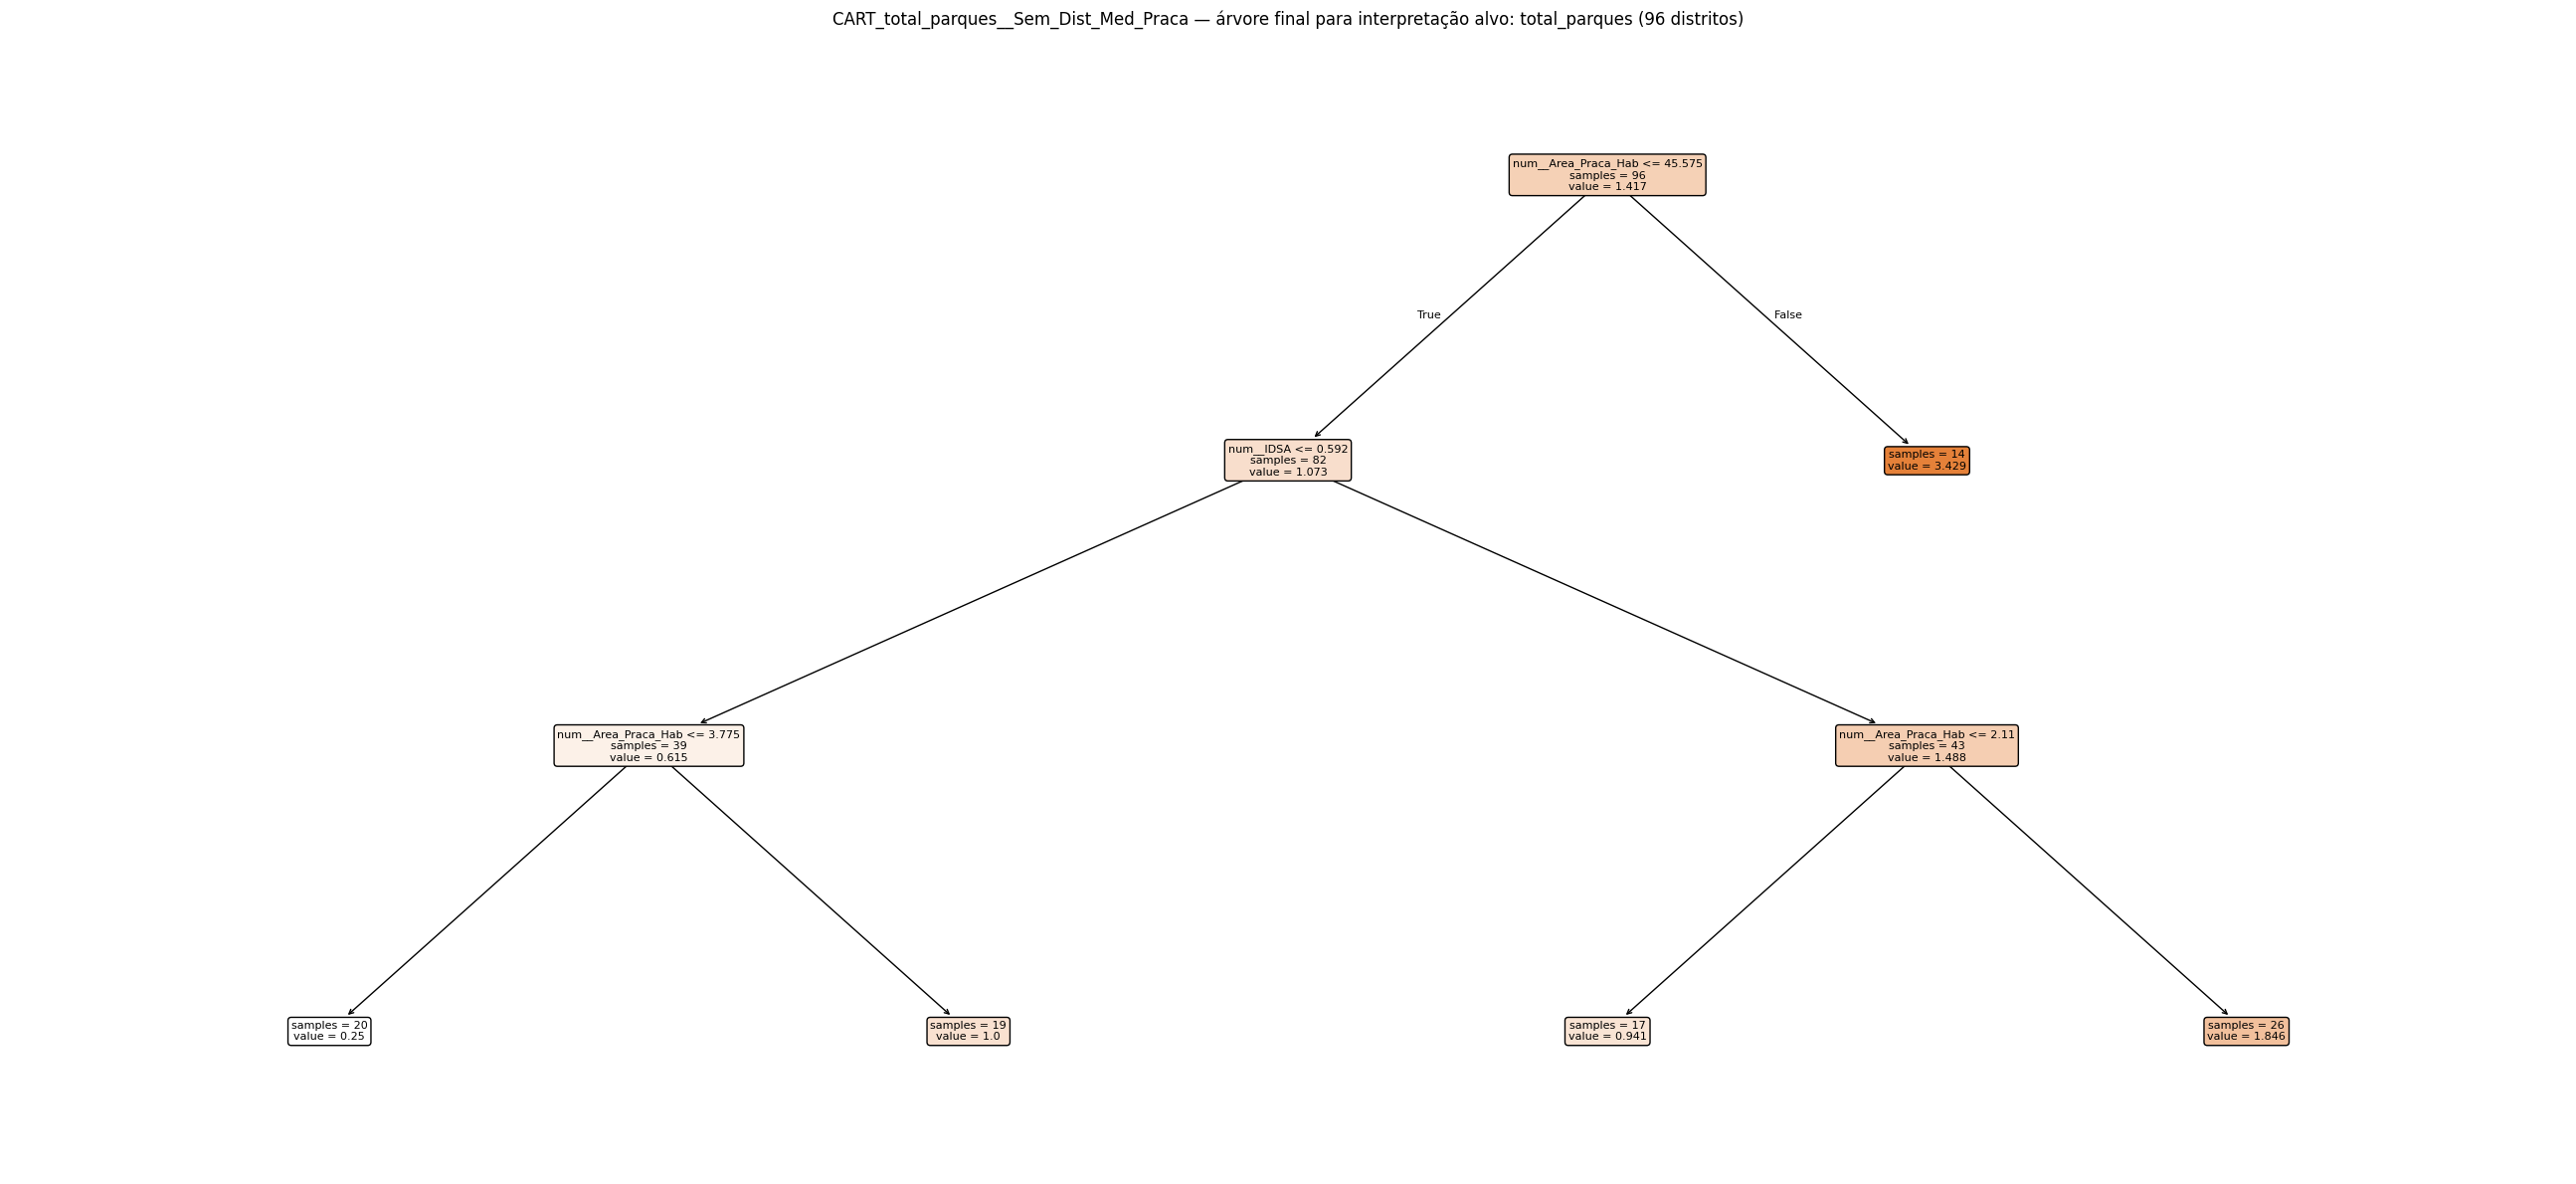

In [ ]:
busca_final = criar_busca()
busca_final.fit(X, y)

modelo_final = busca_final.best_estimator_
arvore_final = modelo_final.named_steps["cart"]

nomes_variaveis = (
    modelo_final.named_steps["preprocessamento"]
    .get_feature_names_out()
)

experimentos[EXPERIMENTO]["modelo_final"] = modelo_final
experimentos[EXPERIMENTO]["parametros_finais"] = (
    busca_final.best_params_.copy()
)

print("Experimento:", EXPERIMENTO)
print("Parâmetros da árvore final:", busca_final.best_params_)
print("Alvo:", ALVO)
print("Unidade de value na árvore:", cfg_alvo["unidade_arvore"])
print("Profundidade:", arvore_final.get_depth())
print("Número de folhas:", arvore_final.get_n_leaves())

plt.figure(figsize=(26, 12))

plot_tree(
    arvore_final,
    feature_names=nomes_variaveis,
    filled=True,
    rounded=True,
    impurity=False,
    precision=3,
    fontsize=8
)

plt.title(
    f"{EXPERIMENTO} — árvore final para interpretação "
    f"alvo: {ALVO} ({len(dados)} distritos)"
)
plt.tight_layout()
plt.show()